In [1]:
%pip install psycopg2-binary

Note: you may need to restart the kernel to use updated packages.


In [2]:
from sqlalchemy import create_engine, URL
from getpass import getpass


password = getpass("Enter PostgreSQL password: ")

connection_url = URL.create(
    drivername="postgresql+psycopg2",
    username="postgres",
    
    password=password,
    host="localhost",
    port=5432,
    database="cruise_intelligence"
)

engine = create_engine(connection_url)

with engine.connect() as connection:
    print("Connected Successfully!")

Enter PostgreSQL password:  ········


Connected Successfully!


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression


query = "SELECT * FROM new_activity_booking"

df = pd.read_sql(query, engine)

print("Dataset loaded successfully!")
print("Rows and Columns:", df.shape)

display(df.head())

Dataset loaded successfully!
Rows and Columns: (730000, 19)


,activity_booking_id,passenger_id,activity_name,activity_category,port_name,booking_date,activity_date,start_time,duration_hours,minimum_age,capacity,activity_price,quantity,total_price,booking_status,payment_status,booking_source,cancellation_reason,port_id
0,1178291,491,Shore Excursion,Wellness,Sydney,2025-04-07,2025-08-12,13:00:00,1.5,12,250,0.0,1,0.0,Confirmed,Paid,Onboard,NaN,15
1,196436,91,Pottery & Ceramics Workshop,Wellness,Vancouver,2025-01-11,2025-10-04,11:00:00,4.0,18,50,300.0,1,300.0,Confirmed,Paid,Website,NaN,19
2,198596,351,Pottery & Ceramics Workshop,Shore Excursion,Colombo,2025-01-11,2025-03-07,18:30:00,4.0,18,50,300.0,1,300.0,Confirmed,Paid,Website,NaN,2
3,1178325,525,Swimming Pool,Indoor Activity,Hamburg,2025-03-26,2025-04-16,11:00:00,1.0,0,100,0.0,1,0.0,Cancelled,Refunded,Website,Passenger Request,5
4,198837,691,Pottery & Ceramics Workshop,Wellness,Mumbai,2025-01-31,2025-03-06,11:00:00,4.0,18,80,300.0,1,300.0,Confirmed,Paid,Website,NaN,1


In [4]:
df

,activity_booking_id,passenger_id,activity_name,activity_category,port_name,booking_date,activity_date,start_time,duration_hours,minimum_age,capacity,activity_price,quantity,total_price,booking_status,payment_status,booking_source,cancellation_reason,port_id
0,1178291,491,Shore Excursion,Wellness,Sydney,2025-04-07,2025-08-12,13:00:00,1.5,12,250,0.0,1,0.0,Confirmed,Paid,Onboard,NaN,15
1,196436,91,Pottery & Ceramics Workshop,Wellness,Vancouver,2025-01-11,2025-10-04,11:00:00,4.0,18,50,300.0,1,300.0,Confirmed,Paid,Website,NaN,19
2,198596,351,Pottery & Ceramics Workshop,Shore Excursion,Colombo,2025-01-11,2025-03-07,18:30:00,4.0,18,50,300.0,1,300.0,Confirmed,Paid,Website,NaN,2
3,1178325,525,Swimming Pool,Indoor Activity,Hamburg,2025-03-26,2025-04-16,11:00:00,1.0,0,100,0.0,1,0.0,Cancelled,Refunded,Website,Passenger Request,5
4,198837,691,Pottery & Ceramics Workshop,Wellness,Mumbai,2025-01-31,2025-03-06,11:00:00,4.0,18,80,300.0,1,300.0,Confirmed,Paid,Website,NaN,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
729995,1177521,1121,Swimming Pool,Indoor Activity,Sydney,2025-07-26,2025-08-10,11:00:00,1.5,12,100,0.0,1,0.0,Confirmed,Paid,Website,NaN,15
729996,1177725,1325,Swimming Pool,Indoor Activity,Dubai,2025-05-15,2025-11-15,11:00:00,1.0,0,100,0.0,1,0.0,Cancelled,Refunded,Website,Passenger Request,20
729997,1177833,33,Swimming Pool,Indoor Activity,Los Angeles,2025-05-21,2025-09-15,11:00:00,3.0,18,100,0.0,1,0.0,Confirmed,Paid,Website,NaN,18
729998,1177900,100,Ocean Theatre Show,Entertainment,Vancouver,2025-04-20,2025-10-04,06:00:00,1.0,0,50,0.0,2,0.0,Cancelled,Refunded,Mobile App,Weather,19


In [5]:
df.shape

(730000, 19)

In [6]:
df.describe()

,activity_booking_id,passenger_id,duration_hours,minimum_age,capacity,activity_price,quantity,total_price,port_id
count,7.300000e+05,730000.000000,730000.000000,730000.000000,730000.000000,730000.000000,730000.000000,730000.000000,730000.000000
mean,7.773293e+05,700.414521,2.423288,15.290411,100.171945,1634.587671,1.053633,1652.776712,10.545455
std,5.354647e+05,404.119226,1.004582,6.049847,73.337051,2152.826759,0.225292,2149.689692,6.272089
min,1.000000e+00,1.000000,1.000000,0.000000,20.000000,0.000000,1.000000,0.000000,1.000000
25%,1.825008e+05,350.000000,1.500000,16.000000,50.000000,0.000000,1.000000,0.000000,5.000000
50%,1.065000e+06,700.000000,2.000000,18.000000,80.000000,750.000000,1.000000,800.000000,10.500000
75%,1.247500e+06,1050.000000,3.000000,18.000000,150.000000,2000.000000,1.000000,2000.000000,16.000000
max,1.430000e+06,1400.000000,4.000000,21.000000,250.000000,7500.000000,2.000000,7500.000000,21.000000


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 730000 entries, 0 to 729999
Data columns (total 19 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   activity_booking_id  730000 non-null  int64  
 1   passenger_id         730000 non-null  int64  
 2   activity_name        730000 non-null  str    
 3   activity_category    730000 non-null  str    
 4   port_name            730000 non-null  str    
 5   booking_date         730000 non-null  object 
 6   activity_date        730000 non-null  object 
 7   start_time           730000 non-null  object 
 8   duration_hours       730000 non-null  float64
 9   minimum_age          730000 non-null  int64  
 10  capacity             730000 non-null  int64  
 11  activity_price       730000 non-null  float64
 12  quantity             730000 non-null  int64  
 13  total_price          730000 non-null  float64
 14  booking_status       730000 non-null  str    
 15  payment_status       730000 

In [8]:
df.isnull().sum()

activity_booking_id         0
passenger_id                0
activity_name               0
activity_category           0
port_name                   0
booking_date                0
activity_date               0
start_time                  0
duration_hours              0
minimum_age                 0
capacity                    0
activity_price              0
quantity                    0
total_price                 0
booking_status              0
payment_status              0
booking_source              0
cancellation_reason    676140
port_id                     0
dtype: int64

In [9]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [10]:
df["booking_date"] = pd.to_datetime(df["booking_date"])
df["activity_date"] = pd.to_datetime(df["activity_date"])

print(df[["booking_date", "activity_date"]].dtypes)

booking_date     datetime64[s]
activity_date    datetime64[s]
dtype: object


In [11]:
print(pd.crosstab(
    df["booking_status"],
    df["cancellation_reason"].isnull()
))

cancellation_reason  False   True 
booking_status                    
Cancelled            53860       0
Completed                0   51149
Confirmed                0  585996
Pending                  0   38995


In [12]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
activity_booking_id,730000.0,777329.267123,1.0,182500.75,1065000.5,1247500.25,1430000.0,535464.733694
passenger_id,730000.0,700.414521,1.0,350.0,700.0,1050.0,1400.0,404.119226
booking_date,730000,2025-03-29 22:13:00,2025-01-01 00:00:00,2025-02-06 00:00:00,2025-03-05 00:00:00,2025-05-13 00:00:00,2025-11-05 00:00:00,NaN
activity_date,730000,2025-06-28 22:54:40,2025-03-06 00:00:00,2025-04-23 00:00:00,2025-06-28 00:00:00,2025-08-20 00:00:00,2025-12-30 00:00:00,NaN
duration_hours,730000.0,2.423288,1.0,1.5,2.0,3.0,4.0,1.004582
minimum_age,730000.0,15.290411,0.0,16.0,18.0,18.0,21.0,6.049847
capacity,730000.0,100.171945,20.0,50.0,80.0,150.0,250.0,73.337051
activity_price,730000.0,1634.587671,0.0,0.0,750.0,2000.0,7500.0,2152.826759
quantity,730000.0,1.053633,1.0,1.0,1.0,1.0,2.0,0.225292
total_price,730000.0,1652.776712,0.0,0.0,800.0,2000.0,7500.0,2149.689692


In [13]:
print(df["minimum_age"].value_counts().sort_index())

minimum_age
0      86000
12     86000
16     86000
18    386000
21     86000
Name: count, dtype: int64


In [14]:
print("Zero Activity Price:",
      (df["activity_price"] == 0).sum())

print("Zero Total Price:",
      (df["total_price"] == 0).sum())

print("Negative Activity Price:",
      (df["activity_price"] < 0).sum())

Zero Activity Price: 200669
Zero Total Price: 200669
Negative Activity Price: 0


In [15]:
df["calculated_price"] = (
    df["activity_price"] * df["quantity"]
)

print(
    "Mismatched Rows:",
    (df["total_price"] != df["calculated_price"]).sum()
)

Mismatched Rows: 0


In [16]:
print(df["activity_category"].value_counts())

activity_category
Wellness           109167
Shore Excursion    109167
Sports             109167
Casino             109167
Entertainment      109166
Indoor Activity     71666
Adventure           37500
Dining              37500
Cultural            37500
Name: count, dtype: int64


In [17]:
print(df["activity_name"].value_counts())

activity_name
Photography Workshop           50833
Fitness & Yoga                 35834
Live Music                     35834
Luxury Spa                     35834
Casino Night                   35834
Shore Excursion                35833
Swimming Pool                  35833
Ocean Theatre Show             35833
Dance Performance              35833
Personal Gym Training          35833
Fine Dining Experience         35833
Art & Craft Workshop           35833
Pottery & Ceramics Workshop    15000
Cooking Masterclass            15000
Live Theatre Show              15000
Casino Evening                 15000
Beach Excursion                15000
Water Sports Adventure         15000
Shopping Excursion             15000
Luxury Spa Session             15000
Swimming Pool Access           15000
Wine Tasting Experience        15000
Museum Visit                   15000
Cultural Heritage Tour         15000
Fitness & Yoga Session         15000
Whale Watching Tour            15000
City Sightseeing Tour   

In [18]:
print(pd.crosstab(
    df["activity_name"],
    df["booking_status"]
))

booking_status               Cancelled  Completed  Confirmed  Pending
activity_name                                                        
Art & Craft Workshop              1433       2491      29886     2023
Beach Excursion                   1836       1068      11364      732
Casino Evening                    1824       1056      11376      744
Casino Night                      1434       2491      29886     2023
City Sightseeing Tour             1836       1068      11364      732
Cooking Masterclass               1836       1056      11376      732
Cultural Heritage Tour            1836       1068      11364      732
Dance Performance                 1433       2491      29885     2024
Fine Dining Experience            1433       2490      29886     2024
Fitness & Yoga                    1434       2490      29886     2024
Fitness & Yoga Session            1836       1068      11364      732
Live Music                        1434       2491      29885     2024
Live Theatre Show   

In [19]:
activity_cancellation = pd.crosstab(
    df["activity_name"],
    df["booking_status"],
    normalize="index"
).mul(100).round(2)

print(activity_cancellation[["Cancelled"]].sort_values(
    by="Cancelled",
    ascending=False
))

booking_status               Cancelled
activity_name                         
Beach Excursion                  12.24
Cooking Masterclass              12.24
City Sightseeing Tour            12.24
Cultural Heritage Tour           12.24
Fitness & Yoga Session           12.24
Local Food Experience            12.24
Museum Visit                     12.24
Shopping Excursion               12.24
Wine Tasting Experience          12.24
Whale Watching Tour              12.24
Water Sports Adventure           12.24
Pottery & Ceramics Workshop      12.24
Rainforest Tour                  12.24
Scenic Harbour Cruise            12.24
Casino Evening                   12.16
Sunset Deck Dinner               12.16
Swimming Pool Access             12.16
Luxury Spa Session               12.16
Live Theatre Show                12.16
Photography Workshop              6.43
Dance Performance                 4.00
Art & Craft Workshop              4.00
Casino Night                      4.00
Luxury Spa               

In [20]:
category_cancellation = pd.crosstab(
    df["activity_category"],
    df["booking_status"],
    normalize="index"
).mul(100).round(2)

print(category_cancellation[["Cancelled"]].sort_values(
    by="Cancelled",
    ascending=False
))

booking_status     Cancelled
activity_category           
Adventure              12.22
Cultural               12.22
Dining                 12.22
Casino                  6.83
Shore Excursion         6.83
Wellness                6.83
Sports                  6.83
Entertainment           6.81
Indoor Activity         4.00


In [21]:
print(pd.crosstab(
    df["booking_source"],
    df["booking_status"]
))

booking_status  Cancelled  Completed  Confirmed  Pending
booking_source                                          
Mobile App          13456      12788     146501     9755
Onboard              4300       7471      89659     6070
Onboard Desk         9168       5316      56844     3672
Reception            4300       7471      89658     6071
Travel Agent         9168       5316      56832     3684
Website             13468      12787     146502     9743


In [22]:
source_cancellation = pd.crosstab(
    df["booking_source"],
    df["booking_status"],
    normalize="index"
).mul(100).round(2)

print(source_cancellation[["Cancelled"]].sort_values(
    by="Cancelled",
    ascending=False
))

booking_status  Cancelled
booking_source           
Travel Agent        12.22
Onboard Desk        12.22
Website              7.38
Mobile App           7.37
Onboard              4.00
Reception            4.00


In [23]:
print(df["payment_status"].value_counts())

payment_status
Paid        637145
Refunded     53860
Pending      38995
Name: count, dtype: int64


In [24]:
print(pd.crosstab(
    df["booking_status"],
    df["payment_status"]
))

payment_status    Paid  Pending  Refunded
booking_status                           
Cancelled            0        0     53860
Completed        51149        0         0
Confirmed       585996        0         0
Pending              0    38995         0


In [25]:
print(pd.crosstab(
    df["booking_source"],
    df["payment_status"]
))

payment_status    Paid  Pending  Refunded
booking_source                           
Mobile App      159289     9755     13456
Onboard          97130     6070      4300
Onboard Desk     62160     3672      9168
Reception        97129     6071      4300
Travel Agent     62148     3684      9168
Website         159289     9743     13468


In [26]:
source_payment = pd.crosstab(
    df["booking_source"],
    df["payment_status"],
    normalize="index"
).mul(100).round(2)

print(source_payment)

payment_status   Paid  Pending  Refunded
booking_source                          
Mobile App      87.28     5.35      7.37
Onboard         90.35     5.65      4.00
Onboard Desk    82.88     4.90     12.22
Reception       90.35     5.65      4.00
Travel Agent    82.86     4.91     12.22
Website         87.28     5.34      7.38


In [27]:
df["booking_month"] = df["booking_date"].dt.month_name()

print(df["booking_month"].value_counts())

booking_month
February     189846
January      154992
March         88515
April         85868
May           65232
June          51255
July          45140
August        28904
September     14145
October        5321
November        782
Name: count, dtype: int64


In [28]:
monthly_bookings = (
    df.groupby("booking_month")["activity_booking_id"]
    .count()
    .reindex([
        "January", "February", "March", "April",
        "May", "June", "July", "August",
        "September", "October", "November", "December"
    ], fill_value=0)
)

print(monthly_bookings)

booking_month
January      154992
February     189846
March         88515
April         85868
May           65232
June          51255
July          45140
August        28904
September     14145
October        5321
November        782
December          0
Name: activity_booking_id, dtype: int64


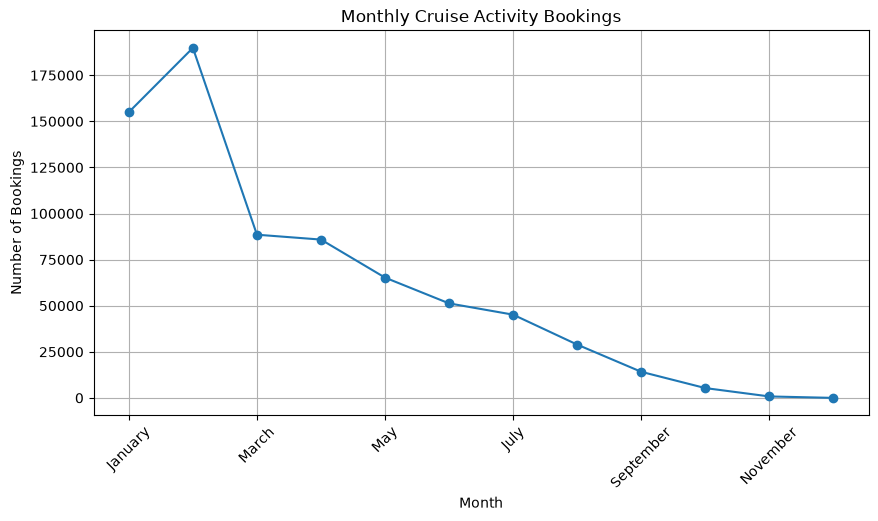

In [29]:
monthly_bookings.plot(
    kind="line",
    marker="o",
    figsize=(10, 5),
    title="Monthly Cruise Activity Bookings"
)

plt.xlabel("Month")
plt.ylabel("Number of Bookings")
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

In [30]:
print(df["activity_date"].dtype)

datetime64[s]


In [31]:
df["activity_date"] = pd.to_datetime(df["activity_date"])

In [32]:
print(df["activity_date"].dtype)

datetime64[s]


In [33]:
df["activity_month"] = df["activity_date"].dt.month_name()

print(df["activity_month"].value_counts())

activity_month
March        132728
August        99546
May           99545
June          99543
April         66364
July          66364
September     66364
October       33182
November      33182
December      33182
Name: count, dtype: int64


In [34]:
print(pd.crosstab(
    df["activity_month"],
    df["booking_status"]
))

booking_status  Cancelled  Completed  Confirmed  Pending
activity_month                                          
April                4897       4652      53272     3543
August               7344       6974      79911     5317
December             2448       2325      26637     1772
July                 4896       4647      53275     3546
June                 7343       6975      79907     5318
March                9795       9303     106542     7088
May                  7345       6973      79908     5319
November             2448       2325      26636     1773
October              2448       2326      26635     1773
September            4896       4649      53273     3546


In [35]:
monthly_cancellation = pd.crosstab(
    df["activity_month"],
    df["booking_status"],
    normalize="index"
).mul(100).round(2)

print(monthly_cancellation[["Cancelled"]])

booking_status  Cancelled
activity_month           
April                7.38
August               7.38
December             7.38
July                 7.38
June                 7.38
March                7.38
May                  7.38
November             7.38
October              7.38
September            7.38


In [36]:
df["booking_lead_days"] = (
    df["activity_date"] - df["booking_date"]
).dt.days

print(df["booking_lead_days"].describe())

count    730000.000000
mean         91.028932
std          85.294072
min           0.000000
25%          20.000000
50%          62.000000
75%         149.000000
max         363.000000
Name: booking_lead_days, dtype: float64


In [37]:
bins = [0, 30, 60, 90, 180, 365]

labels = [
    "0-30 Days",
    "31-60 Days",
    "61-90 Days",
    "91-180 Days",
    "181-365 Days"
]

df["lead_time_group"] = pd.cut(
    df["booking_lead_days"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

print(df["lead_time_group"].value_counts().sort_index())

lead_time_group
0-30 Days       289458
31-60 Days       70987
61-90 Days       68198
91-180 Days     172148
181-365 Days    129209
Name: count, dtype: int64


In [38]:
print(pd.crosstab(
    df["lead_time_group"],
    df["booking_status"],
    normalize="index"
).mul(100).round(2))

booking_status   Cancelled  Completed  Confirmed  Pending
lead_time_group                                          
0-30 Days             4.29       6.98      83.12     5.61
31-60 Days            7.49       7.03      80.16     5.32
61-90 Days            8.64       6.98      79.14     5.24
91-180 Days           9.25       7.02      78.54     5.18
181-365 Days         11.07       7.06      76.86     5.02


In [39]:
print(pd.crosstab(
    df["lead_time_group"],
    df["activity_category"]
))

activity_category  Adventure  Casino  Cultural  Dining  Entertainment  \
lead_time_group                                                         
0-30 Days               2138   48740      2195    2193          46271   
31-60 Days              3900   10598      4070    4075          10282   
61-90 Days              4413    9809      4282    4286          10070   
91-180 Days            13275   23697     13412   13410          24786   
181-365 Days           13774   16323     13541   13536          17757   

activity_category  Indoor Activity  Shore Excursion  Sports  Wellness  
lead_time_group                                                        
0-30 Days                    46596            46111   46274     48940  
31-60 Days                    6698            10331   10276     10757  
61-90 Days                    5394            10115   10082      9747  
91-180 Days                  10425            24662   24785     23696  
181-365 Days                  2553            17948   17

In [40]:
lead_category_pct = pd.crosstab(
    df["lead_time_group"],
    df["activity_category"],
    normalize="index"
).mul(100).round(2)

print(lead_category_pct)

activity_category  Adventure  Casino  Cultural  Dining  Entertainment  \
lead_time_group                                                         
0-30 Days               0.74   16.84      0.76    0.76          15.99   
31-60 Days              5.49   14.93      5.73    5.74          14.48   
61-90 Days              6.47   14.38      6.28    6.28          14.77   
91-180 Days             7.71   13.77      7.79    7.79          14.40   
181-365 Days           10.66   12.63     10.48   10.48          13.74   

activity_category  Indoor Activity  Shore Excursion  Sports  Wellness  
lead_time_group                                                        
0-30 Days                    16.10            15.93   15.99     16.91  
31-60 Days                    9.44            14.55   14.48     15.15  
61-90 Days                    7.91            14.83   14.78     14.29  
91-180 Days                   6.06            14.33   14.40     13.76  
181-365 Days                  1.98            13.89   13

In [41]:
lead_revenue = df.groupby("lead_time_group")["total_price"].agg(
    ["count", "sum", "mean"]
).round(2)

print(lead_revenue)

                  count          sum     mean
lead_time_group                              
0-30 Days        289458  630543200.0  2178.36
31-60 Days        70987  114175150.0  1608.40
61-90 Days        68198  101891500.0  1494.05
91-180 Days      172148  230214650.0  1337.31
181-365 Days     129209  129702500.0  1003.82


In [42]:
print(
    pd.crosstab(
        df["lead_time_group"],
        df["booking_status"],
        normalize="index"
    ).mul(100).round(2)
)

booking_status   Cancelled  Completed  Confirmed  Pending
lead_time_group                                          
0-30 Days             4.29       6.98      83.12     5.61
31-60 Days            7.49       7.03      80.16     5.32
61-90 Days            8.64       6.98      79.14     5.24
91-180 Days           9.25       7.02      78.54     5.18
181-365 Days         11.07       7.06      76.86     5.02


In [43]:
category_revenue = df.groupby("activity_category")["total_price"].agg(
    ["count", "sum", "mean"]
).round(2)

print(category_revenue.sort_values("sum", ascending=False))

                    count          sum     mean
activity_category                              
Casino             109167  439885000.0  4029.47
Entertainment      109166  246362400.0  2256.77
Wellness           109167  207359200.0  1899.47
Sports             109167  128106600.0  1173.49
Shore Excursion    109167   64030600.0   586.54
Dining              37500   32166000.0   857.76
Cultural            37500   32161200.0   857.63
Indoor Activity     71666   28664000.0   399.97
Adventure           37500   27792000.0   741.12


In [44]:
print(
    pd.crosstab(
        df["activity_category"],
        df["booking_status"],
        normalize="index"
    ).mul(100).round(2)
)

booking_status     Cancelled  Completed  Confirmed  Pending
activity_category                                          
Adventure              12.22       7.07      75.78     4.93
Casino                  6.83       7.00      80.78     5.39
Cultural               12.22       7.10      75.78     4.90
Dining                 12.22       7.07      75.81     4.90
Entertainment           6.81       6.99      80.80     5.40
Indoor Activity         4.00       6.95      83.40     5.65
Shore Excursion         6.83       7.00      80.78     5.39
Sports                  6.83       7.00      80.78     5.39
Wellness                6.83       6.99      80.79     5.39


In [45]:
port_revenue = df.groupby("port_name")["total_price"].agg(
    ["count", "sum", "mean"]
).round(2)

print(port_revenue.sort_values("sum", ascending=False))

                count          sum     mean
port_name                                  
Mumbai          66364  109681450.0  1652.73
Sydney          33182   67229250.0  2026.08
Hamburg         33182   67225000.0  2025.95
Southampton     33182   67223600.0  2025.91
Singapore       33182   67222450.0  2025.87
Los Angeles     33182   67221850.0  2025.85
Cape Town       33182   67221600.0  2025.85
Auckland        33182   67221350.0  2025.84
New York        33181   67220950.0  2025.89
Dubai           33182   67220650.0  2025.82
Rio de Janeiro  33181   67214500.0  2025.69
Buenos Aires    33181   42471000.0  1279.98
Honolulu        33182   42465350.0  1279.77
Miami           33181   42464450.0  1279.78
Lisbon          33182   42463100.0  1279.70
Vancouver       33182   42462350.0  1279.68
Rotterdam       33182   42461000.0  1279.64
Durban          33182   42460600.0  1279.63
Manaus          33182   42460250.0  1279.62
Colombo         33182   42459800.0  1279.60
Port Klang      33182   42456450

In [46]:
print(
    pd.crosstab(
        df["port_name"],
        df["booking_status"],
        normalize="index"
    ).mul(100).round(2)
)

booking_status  Cancelled  Completed  Confirmed  Pending
port_name                                               
Auckland             7.38       7.01      80.28     5.34
Buenos Aires         7.37       7.00      80.28     5.34
Cape Town            7.38       7.00      80.28     5.34
Colombo              7.38       7.01      80.27     5.34
Dubai                7.38       7.01      80.27     5.34
Durban               7.38       7.00      80.28     5.34
Hamburg              7.38       7.01      80.27     5.34
Honolulu             7.38       7.01      80.27     5.34
Lisbon               7.38       7.01      80.27     5.34
Los Angeles          7.38       7.00      80.28     5.34
Manaus               7.38       7.00      80.28     5.34
Miami                7.38       7.01      80.27     5.34
Mumbai               7.38       7.01      80.27     5.34
New York             7.37       7.00      80.28     5.34
Port Klang           7.38       7.01      80.27     5.34
Rio de Janeiro       7.38      

In [47]:
passenger_bookings = df.groupby("passenger_id")["activity_booking_id"].count()

print(passenger_bookings.describe().round(2))

count    1400.00
mean      521.43
std         4.20
min       511.00
25%       523.00
50%       523.00
75%       523.00
max       524.00
Name: activity_booking_id, dtype: float64


In [48]:
passenger_status = pd.crosstab(
    df["passenger_id"],
    df["booking_status"]
)

print(passenger_status.head(10))

booking_status  Cancelled  Completed  Confirmed  Pending
passenger_id                                            
1                      24         46        424       30
2                      24         35        435       30
3                      24         35        435       30
4                      24         35        435       30
5                      24         34        424       30
6                      36         47        423       18
7                      24         35        435       30
8                      24         35        435       30
9                      24         34        436       30
10                     24         34        424       30


In [49]:
passenger_revenue = df.groupby("passenger_id")["total_price"].sum()

print(passenger_revenue.sort_values(ascending=False).head(10))

passenger_id
1107    1216500.0
927     1216500.0
1287    1216500.0
87      1206500.0
147     1206500.0
687     1204500.0
7       1204500.0
867     1204500.0
1047    1204500.0
1227    1204500.0
Name: total_price, dtype: float64


In [50]:
paid_passenger_revenue = (
    df[df["payment_status"] == "Paid"]
    .groupby("passenger_id")["total_price"]
    .sum()
)

print(paid_passenger_revenue.sort_values(ascending=False).head(10))

passenger_id
87      1113500.0
7       1111500.0
507     1111500.0
1347    1111500.0
1287    1111500.0
1047    1111500.0
267     1111500.0
1227    1111500.0
127     1111500.0
987     1111500.0
Name: total_price, dtype: float64


In [51]:
print(paid_passenger_revenue.describe().round(2))

count       1400.00
mean      767823.07
std       282786.51
min        84000.00
25%       480000.00
50%       864000.00
75%       994800.00
max      1113500.00
Name: total_price, dtype: float64


In [52]:
print(paid_passenger_revenue.quantile([0.25, 0.50, 0.75]))

0.25    480000.0
0.50    864000.0
0.75    994800.0
Name: total_price, dtype: float64


In [53]:
def passenger_segment(value):
    if value <= 480000:
        return "Low Value"
    elif value <= 864000:
        return "Medium Value"
    else:
        return "High Value"

passenger_segment_df = paid_passenger_revenue.reset_index()
passenger_segment_df.columns = ["passenger_id", "paid_booking_value"]

passenger_segment_df["segment"] = (
    passenger_segment_df["paid_booking_value"].apply(passenger_segment)
)

print(passenger_segment_df["segment"].value_counts())

segment
High Value      688
Low Value       376
Medium Value    336
Name: count, dtype: int64


In [54]:
segment_analysis = passenger_segment_df.groupby("segment")[
    "paid_booking_value"
].agg(["count", "sum", "mean"]).round(2)

print(segment_analysis)

              count          sum       mean
segment                                    
High Value      688  684618500.0  995085.03
Low Value       376  132173400.0  351525.00
Medium Value    336  258160400.0  768334.52


In [55]:
segment_activity = pd.crosstab(
    df["passenger_id"].map(
        passenger_segment_df.set_index("passenger_id")["segment"]
    ),
    df["activity_category"]
)

print(segment_activity)

activity_category  Adventure  Casino  Cultural  Dining  Entertainment  \
passenger_id                                                            
High Value             36000   86382         0       0          41067   
Low Value               1500    4367     35988   35556          37132   
Medium Value               0   18418      1512    1944          30967   

activity_category  Indoor Activity  Shore Excursion  Sports  Wellness  
passenger_id                                                           
High Value                   50366            36795   41066     67096  
Low Value                     2866            37133   37119      4367  
Medium Value                 18434            35239   30982     37704  


In [56]:
print(
    pd.crosstab(
        df["passenger_id"].map(
            passenger_segment_df.set_index("passenger_id")["segment"]
        ),
        df["activity_category"],
        normalize="index"
    ).mul(100).round(2)
)

activity_category  Adventure  Casino  Cultural  Dining  Entertainment  \
passenger_id                                                            
High Value             10.03   24.08      0.00    0.00          11.45   
Low Value               0.77    2.23     18.36   18.14          18.94   
Medium Value            0.00   10.51      0.86    1.11          17.68   

activity_category  Indoor Activity  Shore Excursion  Sports  Wellness  
passenger_id                                                           
High Value                   14.04            10.26   11.45     18.70  
Low Value                     1.46            18.94   18.94      2.23  
Medium Value                 10.52            20.11   17.68     21.52  


In [57]:
print(df.columns.tolist())

['activity_booking_id', 'passenger_id', 'activity_name', 'activity_category', 'port_name', 'booking_date', 'activity_date', 'start_time', 'duration_hours', 'minimum_age', 'capacity', 'activity_price', 'quantity', 'total_price', 'booking_status', 'payment_status', 'booking_source', 'cancellation_reason', 'port_id', 'calculated_price', 'booking_month', 'activity_month', 'booking_lead_days', 'lead_time_group']


In [58]:
passenger_df = pd.read_sql(
    "SELECT * FROM new_passenger LIMIT 5",
    engine
)

print(passenger_df)

   passenger_id    passenger_name  age gender nationality passport_status  \
0          1233     Beatriz Souza   56   Male      Brazil           Valid   
1           238       Eva De Jong   69   Male     Germany           Valid   
2          1182     Sanduni Silva   63   Male      Brazil           Valid   
3           600    Huda Al Nuaimi   59   Male   Singapore           Valid   
4           625  Sophie Schneider   70   Male      France           Valid   

  medical_clearance passenger_status  booking_id booking_date  ...  \
0           Cleared           Active        6233   2025-02-21  ...   
1           Cleared           Active        5238   2025-02-16  ...   
2           Cleared           Active        6182   2025-02-24  ...   
3           Cleared           Active        5600   2025-01-01  ...   
4           Cleared           Active        5625   2025-02-25  ...   

  deck_number  cabin_type cabin_area_sqft occupancy_capacity  sea_view  \
0           4    Interior             320 

In [59]:
passenger_age = passenger_df[["passenger_id", "age"]]

print(passenger_age.head())

   passenger_id  age
0          1233   56
1           238   69
2          1182   63
3           600   59
4           625   70


In [60]:
df = df.merge(
    passenger_age,
    on="passenger_id",
    how="left"
)

In [61]:
print(df[["passenger_id", "age"]].head())
print(df["age"].isnull().sum())

   passenger_id  age
0           491  NaN
1            91  NaN
2           351  NaN
3           525  NaN
4           691  NaN
727397


In [62]:
print("Activity Booking Unique Passengers:",
      df["passenger_id"].nunique())

print("Passenger Table Unique IDs:",
      passenger_age["passenger_id"].nunique())

print("Matching Passenger IDs:",
      df["passenger_id"].isin(
          passenger_age["passenger_id"]
      ).sum())

Activity Booking Unique Passengers: 1400
Passenger Table Unique IDs: 5
Matching Passenger IDs: 2603


In [63]:
passenger_df = pd.read_sql(
    "SELECT passenger_id, age FROM new_passenger",
    engine
)

print(passenger_df.shape)

(1400, 2)


In [64]:
print(passenger_df["passenger_id"].nunique())

1400


In [65]:
print("Duplicate Passenger IDs:", passenger_df["passenger_id"].duplicated().sum())

Duplicate Passenger IDs: 0


In [66]:
print(df["age"].describe())

count    2603.000000
mean       63.420284
std         5.468033
min        56.000000
25%        59.000000
50%        63.000000
75%        69.000000
max        70.000000
Name: age, dtype: float64


In [67]:
bins = [24, 35, 45, 55, 65, 70]

labels = ["25-35", "36-45", "46-55", "56-65", "66-70"]

df["age_group"] = pd.cut(
    df["age"],
    bins=bins,
    labels=labels
)

print(df["age_group"].value_counts().sort_index())

age_group
25-35       0
36-45       0
46-55       0
56-65    1557
66-70    1046
Name: count, dtype: int64


In [68]:
paid_age_analysis = (
    df[df["payment_status"] == "Paid"]
    .groupby("age_group", observed=True)["total_price"]
    .agg(["count", "sum", "mean"])
    .round(2)
)

print(paid_age_analysis)

           count        sum     mean
age_group                           
56-65       1106  2090800.0  1890.42
66-70        648   998400.0  1540.74


In [69]:
print(pd.crosstab(df["age_group"], df["activity_category"]))

activity_category  Adventure  Casino  Cultural  Entertainment  \
age_group                                                       
56-65                    216     103       204            206   
66-70                    216     102         0            102   

activity_category  Indoor Activity  Shore Excursion  Sports  Wellness  
age_group                                                              
56-65                          102              204     420       102  
66-70                          102              103     318       103  


In [70]:
age_activity_pct = (
    pd.crosstab(
        df["age_group"],
        df["activity_category"],
        normalize="index"
    ) * 100
).round(2)

print(age_activity_pct)

activity_category  Adventure  Casino  Cultural  Entertainment  \
age_group                                                       
56-65                  13.87    6.62      13.1          13.23   
66-70                  20.65    9.75       0.0           9.75   

activity_category  Indoor Activity  Shore Excursion  Sports  Wellness  
age_group                                                              
56-65                         6.55            13.10   26.97      6.55  
66-70                         9.75             9.85   30.40      9.85  


In [71]:
pd.crosstab(
    df["age_group"],
    df["booking_status"],
    normalize="index"
).mul(100).round(2)

booking_status,Cancelled,Completed,Confirmed,Pending
age_group,,,,
56-65,24.34,5.20,65.83,4.62
66-70,35.09,5.64,56.31,2.96


In [72]:
pd.crosstab(
    df["age_group"],
    df["lead_time_group"],
    normalize="index"
).mul(100).round(2)

lead_time_group,0-30 Days,31-60 Days,61-90 Days,91-180 Days,181-365 Days
age_group,,,,,
56-65,39.18,8.80,9.25,25.05,17.73
66-70,38.43,9.75,10.52,23.52,17.78


In [73]:
pd.crosstab(
    df["age_group"],
    df["booking_source"],
    normalize="index"
).mul(100).round(2)

booking_source,Mobile App,Onboard Desk,Reception,Travel Agent,Website
age_group,,,,,
56-65,33.59,13.1,19.72,13.87,19.72
66-70,20.65,0.0,29.35,20.65,29.35


In [74]:
pd.crosstab(
    df["age_group"],
    df["port_name"],
    normalize="index"
).mul(100).round(2)

port_name,Auckland,Buenos Aires,Cape Town,Colombo,Dubai,Durban,Hamburg,Honolulu,Lisbon,Los Angeles,...,Miami,Mumbai,New York,Port Klang,Rio de Janeiro,Rotterdam,Singapore,Southampton,Sydney,Vancouver
age_group,,,,,,,,,,,,,,,,,,,,,
56-65,3.53,5.33,3.73,5.46,3.73,5.46,3.73,5.33,5.59,3.60,...,5.39,9.25,3.60,5.33,3.53,5.52,3.60,3.79,3.66,5.39
66-70,4.40,4.59,4.49,4.59,4.49,4.49,4.68,4.40,4.68,4.49,...,4.59,9.08,4.59,4.59,4.59,4.68,4.59,4.59,4.49,4.49


In [75]:
pd.crosstab(
    df["age_group"],
    df["payment_status"],
    normalize="index"
).mul(100).round(2)

payment_status,Paid,Pending,Refunded
age_group,,,
56-65,71.03,4.62,24.34
66-70,61.95,2.96,35.09


In [76]:
age_price_analysis = (
    df.groupby("age_group", observed=True)["activity_price"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

print(age_price_analysis)

           count     mean  median  min     max
age_group                                     
56-65       1557  1449.20  1000.0  0.0  6000.0
66-70       1046  1917.02  1100.0  0.0  6000.0


In [77]:
age_quantity_analysis = (
    df.groupby("age_group", observed=True)["quantity"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

print(age_quantity_analysis)

           count  mean  median  min  max
age_group                               
56-65       1557  1.22     1.0    1    2
66-70       1046  1.02     1.0    1    2


In [78]:
passenger_booking = (
    df.groupby("passenger_id")
    .agg(
        total_bookings=("activity_booking_id", "count"),
        total_paid_value=("total_price", lambda x: x[df.loc[x.index, "payment_status"] == "Paid"].sum())
    )
)

print(passenger_booking.describe().round(2))

       total_bookings  total_paid_value
count         1400.00           1400.00
mean           521.43         767823.07
std              4.20         282786.51
min            511.00          84000.00
25%            523.00         480000.00
50%            523.00         864000.00
75%            523.00         994800.00
max            524.00        1113500.00


In [79]:
top_passengers = passenger_booking.sort_values(
    by="total_paid_value",
    ascending=False
).head(10)

print(top_passengers)

              total_bookings  total_paid_value
passenger_id                                  
87                       524         1113500.0
7                        524         1111500.0
507                      523         1111500.0
1347                     523         1111500.0
1287                     523         1111500.0
1047                     523         1111500.0
267                      523         1111500.0
1227                     523         1111500.0
127                      524         1111500.0
987                      523         1111500.0


In [80]:
bottom_passengers = passenger_booking.sort_values(
    by="total_paid_value",
    ascending=True
).head(10)

print(bottom_passengers)

              total_bookings  total_paid_value
passenger_id                                  
1325                     511           84000.0
425                      523           90000.0
1025                     511           90000.0
725                      523           90000.0
1125                     523           96000.0
1225                     523           96000.0
825                      523           96000.0
125                      524           96000.0
525                      523           96000.0
225                      523           96000.0


In [81]:
passenger_cancellation = (
    df.assign(is_cancelled=df["booking_status"].eq("Cancelled"))
    .groupby("passenger_id")["is_cancelled"]
    .agg(["count", "sum", "mean"])
)

passenger_cancellation["cancellation_pct"] = (
    passenger_cancellation["mean"] * 100
).round(2)

print(passenger_cancellation.head(10))

              count  sum      mean  cancellation_pct
passenger_id                                        
1               524   24  0.045802              4.58
2               524   24  0.045802              4.58
3               524   24  0.045802              4.58
4               524   24  0.045802              4.58
5               512   24  0.046875              4.69
6               524   36  0.068702              6.87
7               524   24  0.045802              4.58
8               524   24  0.045802              4.58
9               524   24  0.045802              4.58
10              512   24  0.046875              4.69


In [82]:
top_cancel_passengers = passenger_cancellation.sort_values(
    by="cancellation_pct",
    ascending=False
).head(10)

print(top_cancel_passengers)

              count  sum      mean  cancellation_pct
passenger_id                                        
125             524  344  0.656489             65.65
1400            523  343  0.655832             65.58
975             523  343  0.655832             65.58
725             523  343  0.655832             65.58
1275            523  343  0.655832             65.58
425             523  343  0.655832             65.58
550             523  343  0.655832             65.58
850             523  343  0.655832             65.58
1150            523  343  0.655832             65.58
1100            523  343  0.655832             65.58


In [83]:
bottom_cancel_passengers = passenger_cancellation.sort_values(
    by="cancellation_pct",
    ascending=True
).head(10)

print(bottom_cancel_passengers)

              count  sum      mean  cancellation_pct
passenger_id                                        
1               524   24  0.045802              4.58
2               524   24  0.045802              4.58
3               524   24  0.045802              4.58
4               524   24  0.045802              4.58
38              524   24  0.045802              4.58
41              524   24  0.045802              4.58
9               524   24  0.045802              4.58
194             524   24  0.045802              4.58
195             524   24  0.045802              4.58
196             524   24  0.045802              4.58


In [84]:
bins = [0, 5, 10, 20, 100]
labels = ["Below 5%", "5-10%", "10-20%", "Above 20%"]

passenger_cancellation["cancellation_group"] = pd.cut(
    passenger_cancellation["cancellation_pct"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

print(passenger_cancellation["cancellation_group"].value_counts().sort_index())

cancellation_group
Below 5%     1100
5-10%         244
10-20%          0
Above 20%      56
Name: count, dtype: int64


In [85]:
high_cancel_ids = passenger_cancellation[
    passenger_cancellation["cancellation_pct"] > 20
].index

high_cancel_df = df[df["passenger_id"].isin(high_cancel_ids)]

print(
    high_cancel_df[high_cancel_df["booking_status"] == "Cancelled"]
    ["activity_category"]
    .value_counts()
)

activity_category
Sports             3059
Casino             3059
Wellness           3047
Shore Excursion    3047
Entertainment      3046
Indoor Activity    2866
Dining              192
Cultural            180
Adventure           180
Name: count, dtype: int64


In [86]:
print(
    high_cancel_df[
        high_cancel_df["booking_status"] == "Cancelled"
    ]["booking_source"].value_counts()
)

booking_source
Mobile App      4672
Website         4660
Onboard         4300
Reception       4300
Onboard Desk     372
Travel Agent     372
Name: count, dtype: int64


In [87]:
source_cancellation = pd.crosstab(
    high_cancel_df["booking_source"],
    high_cancel_df["booking_status"],
    normalize="index"
).mul(100).round(2)

print(source_cancellation)

booking_status  Cancelled  Completed  Confirmed  Pending
booking_source                                          
Mobile App          64.00       2.96      31.07     1.97
Onboard            100.00       0.00       0.00     0.00
Onboard Desk        12.40       6.80      76.00     4.80
Reception          100.00       0.00       0.00     0.00
Travel Agent        12.40       7.20      75.60     4.80
Website             63.84       2.79      31.23     2.14


In [88]:
print(
    high_cancel_df["age_group"].value_counts().sort_index()
)

age_group
25-35      0
36-45      0
46-55      0
56-65    511
66-70    523
Name: count, dtype: int64


In [89]:
high_cancel_df.groupby("age_group")["passenger_id"].nunique()

age_group
56-65    1
66-70    1
Name: passenger_id, dtype: int64

In [90]:
df["is_cancelled"] = (
    df["booking_status"] == "Cancelled"
).astype(int)

print(df["is_cancelled"].value_counts())

print("\nPercentage:")
print(
    df["is_cancelled"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

is_cancelled
0    676140
1     53860
Name: count, dtype: int64

Percentage:
is_cancelled
0    92.62
1     7.38
Name: proportion, dtype: float64


In [91]:
print(df.columns.tolist())

['activity_booking_id', 'passenger_id', 'activity_name', 'activity_category', 'port_name', 'booking_date', 'activity_date', 'start_time', 'duration_hours', 'minimum_age', 'capacity', 'activity_price', 'quantity', 'total_price', 'booking_status', 'payment_status', 'booking_source', 'cancellation_reason', 'port_id', 'calculated_price', 'booking_month', 'activity_month', 'booking_lead_days', 'lead_time_group', 'age', 'age_group', 'is_cancelled']


In [92]:
drop_cols = [
    "activity_booking_id",
    "passenger_id",
    "booking_date",
    "activity_date",
    "total_price",
    "booking_status",
    "payment_status",
    "cancellation_reason",
    "port_id",
    "calculated_price",
    "booking_month",
    "activity_month",
    "lead_time_group",
    "age_group"
]

df = df.drop(columns=drop_cols, errors="ignore")

print(df.shape)
print(df.columns.tolist())

(730000, 13)
['activity_name', 'activity_category', 'port_name', 'start_time', 'duration_hours', 'minimum_age', 'capacity', 'activity_price', 'quantity', 'booking_source', 'booking_lead_days', 'age', 'is_cancelled']


In [93]:
print(df.shape)
print(df.columns.tolist())

(730000, 13)
['activity_name', 'activity_category', 'port_name', 'start_time', 'duration_hours', 'minimum_age', 'capacity', 'activity_price', 'quantity', 'booking_source', 'booking_lead_days', 'age', 'is_cancelled']


In [94]:
numeric_cols = df.select_dtypes(include=["int64", "float64"]).columns

print(numeric_cols.tolist())

['duration_hours', 'minimum_age', 'capacity', 'activity_price', 'quantity', 'booking_lead_days', 'age', 'is_cancelled']


In [95]:
numeric_features = df.select_dtypes(include=["number"]).columns.tolist()

numeric_features
df[numeric_features].isnull().sum()

duration_hours            0
minimum_age               0
capacity                  0
activity_price            0
quantity                  0
booking_lead_days         0
age                  727397
is_cancelled              0
dtype: int64

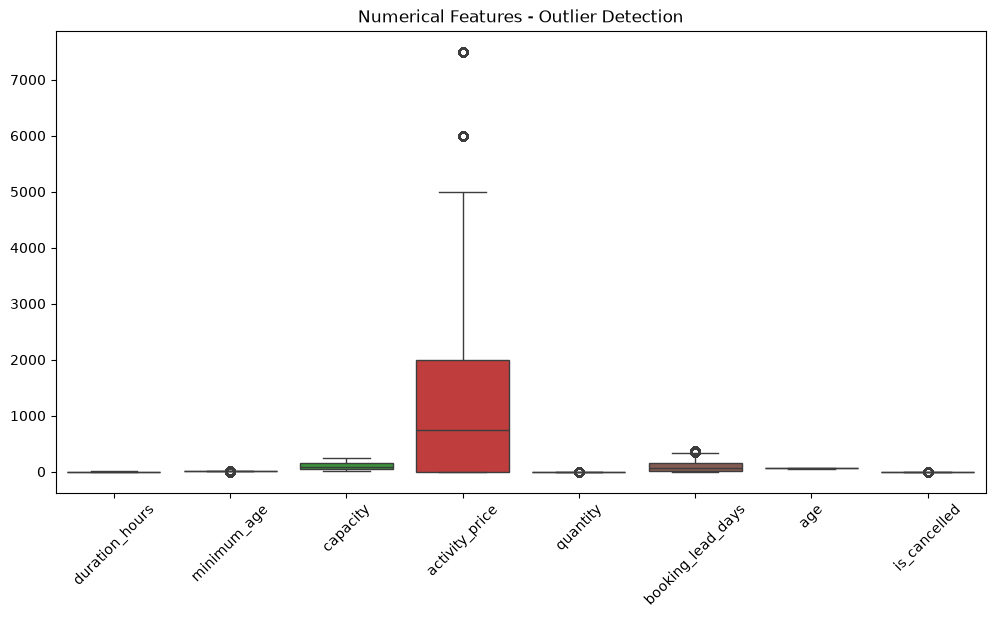

In [96]:



plt.figure(figsize=(12, 6))

sns.boxplot(data=df[numeric_features])

plt.xticks(rotation=45)
plt.title("Numerical Features - Outlier Detection")
plt.show()

In [97]:
print("DataFrame Columns:")
print(df.columns.tolist())

print("\nMissing Columns:")

print(set(numeric_features) - set(df.columns))

DataFrame Columns:
['activity_name', 'activity_category', 'port_name', 'start_time', 'duration_hours', 'minimum_age', 'capacity', 'activity_price', 'quantity', 'booking_source', 'booking_lead_days', 'age', 'is_cancelled']

Missing Columns:
set()


In [98]:
numeric_features = df.select_dtypes(include="number").columns.tolist()

for col in numeric_features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)].shape[0]

    print(col, ":", outliers)

duration_hours : 0
minimum_age : 172000
capacity : 0
activity_price : 71667
quantity : 39152
booking_lead_days : 4772
age : 0
is_cancelled : 53860


In [99]:
categorical_cols = [
    "activity_name",
    "activity_category",
    "port_name",
    "start_time",
    "booking_source"
]

print(df[categorical_cols].isnull().sum())

activity_name        0
activity_category    0
port_name            0
start_time           0
booking_source       0
dtype: int64


In [100]:
for col in categorical_cols:

    print(f"\n{col}")
    print("Unique Count:", df[col].nunique())
    print(df[col].value_counts())


activity_name
Unique Count: 31
activity_name
Photography Workshop           50833
Fitness & Yoga                 35834
Live Music                     35834
Luxury Spa                     35834
Casino Night                   35834
Shore Excursion                35833
Swimming Pool                  35833
Ocean Theatre Show             35833
Dance Performance              35833
Personal Gym Training          35833
Fine Dining Experience         35833
Art & Craft Workshop           35833
Pottery & Ceramics Workshop    15000
Cooking Masterclass            15000
Live Theatre Show              15000
Casino Evening                 15000
Beach Excursion                15000
Water Sports Adventure         15000
Shopping Excursion             15000
Luxury Spa Session             15000
Swimming Pool Access           15000
Wine Tasting Experience        15000
Museum Visit                   15000
Cultural Heritage Tour         15000
Fitness & Yoga Session         15000
Whale Watching Tour          

In [101]:
for col in df.columns:
    if df[col].nunique() == 1:
        print(col, ":", df[col].unique())

In [102]:
df = df.drop(columns=drop_cols, errors="ignore")

print(df.shape)
print(df.columns.tolist())

(730000, 13)
['activity_name', 'activity_category', 'port_name', 'start_time', 'duration_hours', 'minimum_age', 'capacity', 'activity_price', 'quantity', 'booking_source', 'booking_lead_days', 'age', 'is_cancelled']


In [103]:
X = df.drop(columns=["is_cancelled"])
y = df["is_cancelled"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (730000, 12)
y shape: (730000,)


In [104]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (584000, 12)
X_test: (146000, 12)
y_train: (584000,)
y_test: (146000,)


In [105]:
numeric_cols = X_train.select_dtypes(include=["number"]).columns.tolist()

categorical_cols = X_train.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

print("Numerical Columns:", numeric_cols)
print("Categorical Columns:", categorical_cols)

Numerical Columns: ['duration_hours', 'minimum_age', 'capacity', 'activity_price', 'quantity', 'booking_lead_days', 'age']
Categorical Columns: ['activity_name', 'activity_category', 'port_name', 'start_time', 'booking_source']


In [106]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
    ]
)

print("Preprocessor created successfully")

Preprocessor created successfully


In [107]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), numeric_cols),

        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical_cols)
    ]
)

In [108]:
lr_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

In [129]:
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("Accuracy:", accuracy_score(y_test, y_pred))

Confusion Matrix:
[[68729 66499]
 [    0 10772]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.51      0.67    135228
           1       0.14      1.00      0.24     10772

    accuracy                           0.54    146000
   macro avg       0.57      0.75      0.46    146000
weighted avg       0.94      0.54      0.64    146000

Accuracy: 0.544527397260274


In [130]:
from sklearn.metrics import precision_score, recall_score, f1_score

for threshold in [0.3, 0.4, 0.5, 0.6]:

    y_pred_threshold = (y_prob >= threshold).astype(int)

    print("Threshold:", threshold)
    print("Precision:", precision_score(y_test, y_pred_threshold))
    print("Recall:", recall_score(y_test, y_pred_threshold))
    print("F1 Score:", f1_score(y_test, y_pred_threshold))
    print("----------------------")

Threshold: 0.3
Precision: 0.13940546906342613
Recall: 1.0
F1 Score: 0.24469861317765182
----------------------
Threshold: 0.4
Precision: 0.13940546906342613
Recall: 1.0
F1 Score: 0.24469861317765182
----------------------
Threshold: 0.5
Precision: 0.13940546906342613
Recall: 1.0
F1 Score: 0.24469861317765182
----------------------
Threshold: 0.6
Precision: 0.13946168592300917
Recall: 0.9995358336427775
F1 Score: 0.24477130126398108
----------------------


In [131]:
import pandas as pd

print(
    pd.Series(y_prob).describe(
        percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
    )
)

count    1.460000e+05
mean     3.509215e-01
std      3.327881e-01
min      3.268883e-07
10%      4.508879e-06
25%      6.534968e-05
50%      6.256452e-01
75%      6.382699e-01
90%      7.500595e-01
95%      7.595235e-01
99%      7.675161e-01
max      8.257401e-01
dtype: float64


In [132]:
for t in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    print(t, (y_prob >= t).sum())

0.3 77271
0.4 77271
0.5 77271
0.6 77204
0.7 17110
0.8 68


In [133]:
from sklearn.metrics import confusion_matrix, classification_report

y_pred_07 = (y_prob >= 0.7).astype(int)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_07))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_07))

Confusion Matrix:
[[121525  13703]
 [  7365   3407]]

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.90      0.92    135228
           1       0.20      0.32      0.24     10772

    accuracy                           0.86    146000
   macro avg       0.57      0.61      0.58    146000
weighted avg       0.89      0.86      0.87    146000



In [134]:
y_pred = lr_pipeline.predict(X_test)

print("Prediction completed")

Prediction completed


In [139]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nAccuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Confusion Matrix:
[[68729 66499]
 [    0 10772]]

Accuracy: 0.544527397260274
Precision: 0.13940546906342613
Recall: 1.0
F1 Score: 0.24469861317765182

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.51      0.67    135228
           1       0.14      1.00      0.24     10772

    accuracy                           0.54    146000
   macro avg       0.57      0.75      0.46    146000
weighted avg       0.94      0.54      0.64    146000



In [135]:
lr_pipeline.fit(X_train, y_train)

print("Logistic Regression Training Completed")

Logistic Regression Training Completed


In [136]:
y_pred = lr_pipeline.predict(X_test)

print("Prediction Completed")

Prediction Completed


In [137]:
y_prob = lr_pipeline.predict_proba(X_test)[:, 1]

print("Probability calculated")
print(y_prob[:10])

Probability calculated
[4.56203989e-06 6.30633130e-01 6.40066456e-01 6.32336193e-01
 6.42116066e-01 8.89041943e-04 6.30670542e-01 2.53758174e-05
 6.35920637e-01 6.66619658e-01]


In [138]:
from sklearn.metrics import precision_score, recall_score, f1_score

for threshold in [0.3, 0.4, 0.5, 0.6]:
    y_pred_threshold = (y_prob >= threshold).astype(int)

    print("Threshold:", threshold)
    print("Precision:", precision_score(y_test, y_pred_threshold))
    print("Recall:", recall_score(y_test, y_pred_threshold))
    print("F1 Score:", f1_score(y_test, y_pred_threshold))
    print("----------------")

Threshold: 0.3
Precision: 0.13940546906342613
Recall: 1.0
F1 Score: 0.24469861317765182
----------------
Threshold: 0.4
Precision: 0.13940546906342613
Recall: 1.0
F1 Score: 0.24469861317765182
----------------
Threshold: 0.5
Precision: 0.13940546906342613
Recall: 1.0
F1 Score: 0.24469861317765182
----------------
Threshold: 0.6
Precision: 0.13946168592300917
Recall: 0.9995358336427775
F1 Score: 0.24477130126398108
----------------


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nAccuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))